
# ¿Qué grupos de estaciones comparten patrones de uso y dónde se ubican en la ciudad?

## P3. Agrupamiento de estaciones por patrones de uso

### Objetivo

Identificar grupos de estaciones de MiBici con características de uso similares mediante K-Means, para apoyar el análisis de la distribución de la demanda y explorar oportunidades de expansión del sistema.


In [1]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from IPython.display import display


c:\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:

# Ruta al archivo de características generado por P3
ruta_features = Path("../data/processed/p3_station_features.csv")

# Cargar los datos
df = pd.read_csv(ruta_features)

# Mostrar dimensiones y primeras filas
print(f"Dimensiones del conjunto de datos: {df.shape}")
display(df.head())


Dimensiones del conjunto de datos: (471, 12)


,Estacion_Id,viajes_salida,salidas_manana,salidas_tarde,salidas_noche,salidas_madrugada,salidas_fin_semana,duracion_promedio,Nombre,Latitud,Longitud,viajes_llegada
0,2,6217,2379,2238,1557,43,1220,10.950134,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,6277
1,3,5627,1470,2177,1887,93,1091,9.725001,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,4921
2,4,7506,2010,2953,2447,96,1721,10.725588,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,7554
3,5,6310,2672,2271,1203,164,1131,10.406331,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,6597
4,6,4228,1533,1500,1122,73,919,9.943590,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,5404


In [3]:

# Revisar tipos de datos y valores no nulos
print("Información general del conjunto de datos:")
df.info()

print("\nValores faltantes por columna:")
display(df.isnull().sum().to_frame(name="valores_faltantes"))

print("\nEstadísticas descriptivas:")
display(df.describe().T)


Información general del conjunto de datos:
<class 'pandas.DataFrame'>
RangeIndex: 471 entries, 0 to 470
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Estacion_Id         471 non-null    int64  
 1   viajes_salida       471 non-null    int64  
 2   salidas_manana      471 non-null    int64  
 3   salidas_tarde       471 non-null    int64  
 4   salidas_noche       471 non-null    int64  
 5   salidas_madrugada   471 non-null    int64  
 6   salidas_fin_semana  471 non-null    int64  
 7   duracion_promedio   471 non-null    float64
 8   Nombre              469 non-null    str    
 9   Latitud             469 non-null    float64
 10  Longitud            469 non-null    float64
 11  viajes_llegada      471 non-null    int64  
dtypes: float64(3), int64(8), str(1)
memory usage: 63.5 KB

Valores faltantes por columna:


,valores_faltantes
Estacion_Id,0
viajes_salida,0
salidas_manana,0
salidas_tarde,0
salidas_noche,0
salidas_madrugada,0
salidas_fin_semana,0
duracion_promedio,0
Nombre,2
Latitud,2



Estadísticas descriptivas:


,count,mean,std,min,25%,50%,75%,max
Estacion_Id,471.0,257.953291,148.623965,2.000000,133.500000,259.000000,383.500000,519.000000
viajes_salida,471.0,3453.040340,3809.893279,3.000000,1011.500000,2291.000000,4658.500000,40605.000000
salidas_manana,471.0,1083.080679,1227.544306,0.000000,329.000000,706.000000,1435.000000,14793.000000
salidas_tarde,471.0,1328.978769,1418.299023,0.000000,372.000000,837.000000,1881.500000,12974.000000
salidas_noche,471.0,987.643312,1200.124956,3.000000,251.500000,607.000000,1281.000000,11984.000000
salidas_madrugada,471.0,53.337580,70.050428,0.000000,10.000000,31.000000,69.000000,854.000000
salidas_fin_semana,471.0,753.934183,935.837667,0.000000,219.500000,470.000000,923.000000,10468.000000
duracion_promedio,471.0,10.981103,1.784498,6.147415,9.797429,10.750370,11.992393,19.861111
Latitud,469.0,20.678207,0.021613,20.636130,20.665100,20.674140,20.687950,20.739523
Longitud,469.0,-103.362094,0.031647,-103.433215,-103.384221,-103.362351,-103.339378,-103.297112



## Exploración y calidad de los datos

El conjunto de datos contiene 471 estaciones y 12 columnas con información de uso, duración promedio y ubicación geográfica.

Las variables numéricas de uso no presentan valores faltantes. Sin embargo, dos estaciones no tienen nombre ni coordenadas geográficas, por lo que no podrán mostrarse en el mapa.

Se observa una variación considerable en el volumen de viajes entre estaciones. Por ejemplo, el número de viajes de salida va de 3 a 40,605. Por esta razón, es importante escalar las variables numéricas utilizadas por K-Means para evitar que las diferencias de magnitud dominen el agrupamiento.


## Preparación de variables y selección del modelo

Para agrupar las estaciones, se utilizan variables que describen sus patrones de uso, incluyendo las proporciones de viajes por periodo, los viajes de salida y llegada, y la duración promedio. Los volúmenes de viajes se transforman mediante `log1p` para reducir el efecto de valores muy elevados.

Posteriormente, se aplica `StandardScaler` para estandarizar las variables y evitar que sus diferentes escalas dominen el cálculo de distancias de K-Means.

Para seleccionar el número de grupos, se evalúan distintos valores de \(k\), desde 2 hasta 8, utilizando el *silhouette score*. Se elige el valor que obtiene la puntuación más alta entre las alternativas evaluadas.

In [4]:
# Importar la función de preparación utilizada por el modelo P3
from mibici.modeling.p3.train import prepare_features

# Preparar las variables con la misma lógica del entrenamiento
df_preparado, feature_columns = prepare_features(df)

# Mostrar las variables utilizadas por K-Means
print(f"Número de variables utilizadas: {len(feature_columns)}")
print("\nVariables del modelo:")
for columna in feature_columns:
    print(f"- {columna}")

# Mostrar una muestra de las variables preparadas
display(df_preparado[feature_columns].head())

2026-10-16 21:15:53.717 | INFO     | mibici.config:<module>:11 - PROJ_ROOT path is: C:\Users\hp\Documents\TEC\Materia 7 - MLOps\TC5061-Proyecto-Equipo41


Número de variables utilizadas: 8

Variables del modelo:
- salidas_manana_proporcion
- salidas_tarde_proporcion
- salidas_noche_proporcion
- salidas_madrugada_proporcion
- salidas_fin_semana_proporcion
- duracion_promedio
- log_viajes_salida
- log_viajes_llegada


,salidas_manana_proporcion,salidas_tarde_proporcion,salidas_noche_proporcion,salidas_madrugada_proporcion,salidas_fin_semana_proporcion,duracion_promedio,log_viajes_salida,log_viajes_llegada
0,0.382660,0.359981,0.250442,0.006917,0.196236,10.950134,8.735204,8.744807
1,0.261240,0.386885,0.335347,0.016527,0.193887,9.725001,8.635509,8.501470
2,0.267786,0.393419,0.326006,0.012790,0.229283,10.725588,8.923591,8.929965
3,0.423455,0.359905,0.190650,0.025990,0.179239,10.406331,8.750049,8.794522
4,0.362583,0.354778,0.265374,0.017266,0.217360,9.943590,8.349721,8.595080


In [5]:
# Verificar valores faltantes en las variables del modelo
faltantes = df_preparado[feature_columns].isnull().sum()

print("Valores faltantes por variable:")
display(faltantes.to_frame(name="valores_faltantes"))

print(
    "\nTotal de valores faltantes:",
    int(faltantes.sum())
)

Valores faltantes por variable:


,valores_faltantes
salidas_manana_proporcion,0
salidas_tarde_proporcion,0
salidas_noche_proporcion,0
salidas_madrugada_proporcion,0
salidas_fin_semana_proporcion,0
duracion_promedio,0
log_viajes_salida,0
log_viajes_llegada,0



Total de valores faltantes: 0


In [6]:
from sklearn.preprocessing import StandardScaler

# Escalar las variables utilizadas por K-Means
scaler = StandardScaler()
X = scaler.fit_transform(df_preparado[feature_columns])

print(f"Dimensiones de la matriz escalada: {X.shape}")
print(f"Media aproximada de las variables: {X.mean(axis=0).round(4)}")
print(f"Desviación estándar de las variables: {X.std(axis=0).round(4)}")

Dimensiones de la matriz escalada: (471, 8)
Media aproximada de las variables: [-0. -0. -0.  0.  0. -0.  0. -0.]
Desviación estándar de las variables: [1. 1. 1. 1. 1. 1. 1. 1.]


In [7]:
# Cargar los resultados de selección del modelo
ruta_scores = Path("../data/processed/p3_silhouette_scores.csv")
scores_df = pd.read_csv(ruta_scores)

# Mostrar puntuaciones
display(scores_df.sort_values("k"))

# Identificar el número de clusters con mejor puntuación
mejor_fila = scores_df.loc[scores_df["silhouette_score"].idxmax()]

print(f"Mejor número de clusters (k): {int(mejor_fila['k'])}")
print(f"Silhouette score: {mejor_fila['silhouette_score']:.4f}")

,k,silhouette_score
0,2,0.245648
1,3,0.223274
2,4,0.185630
3,5,0.191218
4,6,0.204025
5,7,0.179685
6,8,0.167181


Mejor número de clusters (k): 2
Silhouette score: 0.2456


In [8]:
# Visualizar el silhouette score para cada número de clusters
plt.figure(figsize=(8, 5))

plt.plot(
    scores_df["k"],
    scores_df["silhouette_score"],
    marker="o"
)

plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Selección del número de clusters para P3")
plt.xticks(scores_df["k"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\hp\AppData\Local\Temp\ipykernel_16812\3424656946.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [9]:
from IPython.display import display

display(scores_df.plot(
    x="k",
    y="silhouette_score",
    kind="line",
    marker="o",
    title="Selección del número de clusters para P3",
    xlabel="Número de clusters (k)",
    ylabel="Silhouette score",
    grid=True,
    legend=False,
    figsize=(8, 5)
).figure)

<Figure size 800x500 with 1 Axes>

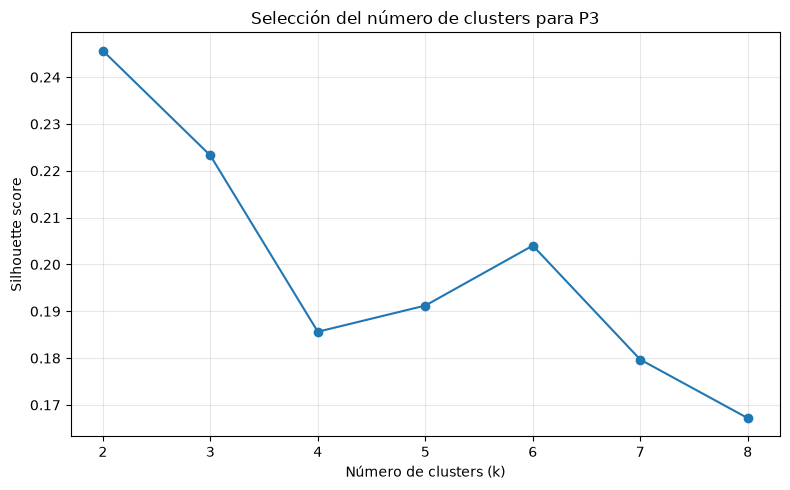

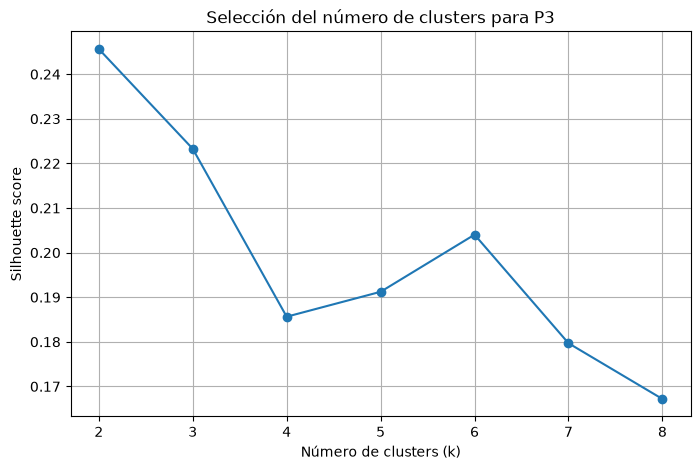

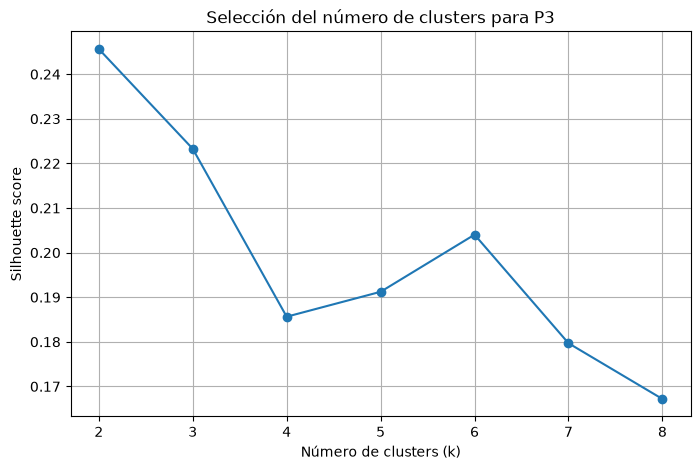

In [10]:
%matplotlib inline

scores_df.plot(
    x="k",
    y="silhouette_score",
    kind="line",
    marker="o",
    title="Selección del número de clusters para P3",
    xlabel="Número de clusters (k)",
    ylabel="Silhouette score",
    grid=True,
    legend=False,
    figsize=(8, 5)
);

### Resultados de la selección del número de clusters

La gráfica muestra que \(k=2\) obtiene el mayor *silhouette score* (0.2456) entre los valores evaluados de 2 a 8 clusters. Por esta razón, se seleccionan dos grupos para el análisis de las estaciones de MiBici.

La puntuación obtenida indica que la separación entre los grupos es limitada. Por lo tanto, los clusters se interpretarán como una aproximación a los patrones de uso de las estaciones, y no como categorías completamente diferenciadas.

In [11]:
# Cargar las etiquetas generadas por el entrenamiento de P3
ruta_clusters = Path("../data/processed/p3_station_clusters.csv")
clusters_df = pd.read_csv(ruta_clusters)

# Revisar las primeras filas y las columnas disponibles
print("Dimensiones del archivo:", clusters_df.shape)
print("Columnas:", clusters_df.columns.tolist())

display(clusters_df.head())

Dimensiones del archivo: (471, 13)
Columnas: ['Estacion_Id', 'viajes_salida', 'salidas_manana', 'salidas_tarde', 'salidas_noche', 'salidas_madrugada', 'salidas_fin_semana', 'duracion_promedio', 'Nombre', 'Latitud', 'Longitud', 'viajes_llegada', 'cluster']


,Estacion_Id,viajes_salida,salidas_manana,salidas_tarde,salidas_noche,salidas_madrugada,salidas_fin_semana,duracion_promedio,Nombre,Latitud,Longitud,viajes_llegada,cluster
0,2,6217,2379,2238,1557,43,1220,10.950134,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,6277,0
1,3,5627,1470,2177,1887,93,1091,9.725001,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,4921,0
2,4,7506,2010,2953,2447,96,1721,10.725588,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,7554,0
3,5,6310,2672,2271,1203,164,1131,10.406331,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,6597,0
4,6,4228,1533,1500,1122,73,919,9.943590,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,5404,0


In [12]:
# Contar estaciones asignadas a cada cluster
print("Número de estaciones por cluster:")
display(
    clusters_df["cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .to_frame(name="numero_estaciones")
)

# Comparar los patrones de uso entre clusters
columnas_comparacion = [
    "viajes_salida",
    "viajes_llegada",
    "salidas_manana",
    "salidas_tarde",
    "salidas_noche",
    "salidas_madrugada",
    "salidas_fin_semana",
    "duracion_promedio",
]

resumen_clusters = clusters_df.groupby("cluster")[columnas_comparacion].mean()

print("\nPromedios por cluster:")
display(resumen_clusters.round(2))

Número de estaciones por cluster:


,numero_estaciones
cluster,
0,278
1,193



Promedios por cluster:


,viajes_salida,viajes_llegada,salidas_manana,salidas_tarde,salidas_noche,salidas_madrugada,salidas_fin_semana,duracion_promedio
cluster,,,,,,,,
0,5080.12,5074.35,1528.26,1998.94,1478.63,74.29,1091.30,10.94
1,1109.37,1117.68,441.84,363.96,280.41,23.15,267.99,11.04


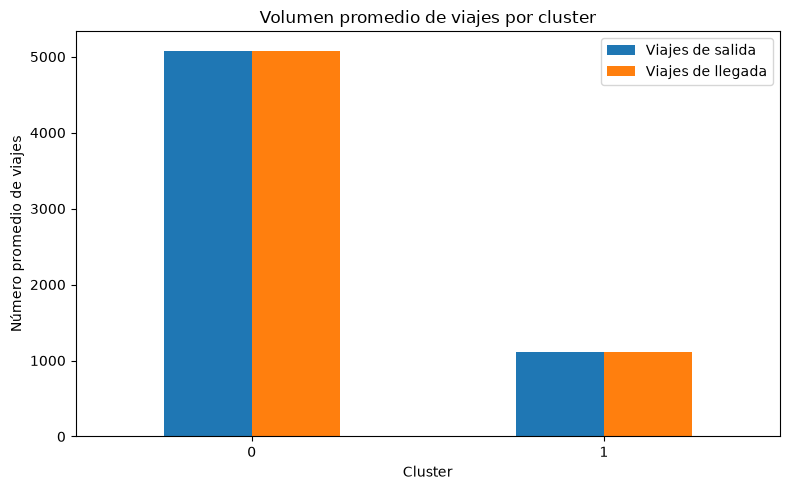

In [13]:
# Comparar el volumen promedio de viajes por cluster
resumen_clusters[
    ["viajes_salida", "viajes_llegada"]
].plot(
    kind="bar",
    figsize=(8, 5),
    title="Volumen promedio de viajes por cluster",
    xlabel="Cluster",
    ylabel="Número promedio de viajes",
    rot=0
);

plt.legend(["Viajes de salida", "Viajes de llegada"])
plt.tight_layout()

## Conclusiones

El análisis de agrupamiento permitió clasificar las 471 estaciones de MiBici en dos grupos según sus patrones de uso, utilizando K-Means y variables relacionadas con los horarios, el volumen de viajes y la duración promedio.

El cluster 0 agrupa 278 estaciones de mayor volumen de uso, con un promedio de 5,080 viajes de salida y 5,074 viajes de llegada. Por su parte, el cluster 1 contiene 193 estaciones de menor volumen, con promedios de 1,109 viajes de salida y 1,118 viajes de llegada.

La duración promedio de los viajes es similar en ambos grupos, por lo que la principal diferencia observada corresponde al volumen de actividad. La selección de dos clusters obtuvo un *silhouette score* de 0.2456, el mejor entre los valores evaluados, aunque la puntuación sugiere que la separación entre los grupos es limitada.

Estos resultados permiten identificar estaciones con diferentes niveles de demanda y pueden servir como punto de partida para investigar oportunidades de redistribución de bicicletas, mejorar la disponibilidad y evaluar posibles expansiones del sistema. Sin embargo, estas decisiones requieren análisis adicionales de ubicación, capacidad y demanda.